# **Partie I: Construction d'un CNN pour une classification multiclasse**

In [ ]:
# Q1) IMPORTATION DES BIBLIOTHÈQUES

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
# CHARGEMENT DU DATASET
dataset, info = tfds.load("tf_flowers", with_info=True, as_supervised=True)
# Le dataset est fourni dans un seul ensemble "train"
data = dataset["train"]
print("Nombre total d'images :", info.splits["train"].num_examples)
print("Noms des classes :", info.features["label"].names)

Nombre total d'images : 3670
Noms des classes : ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


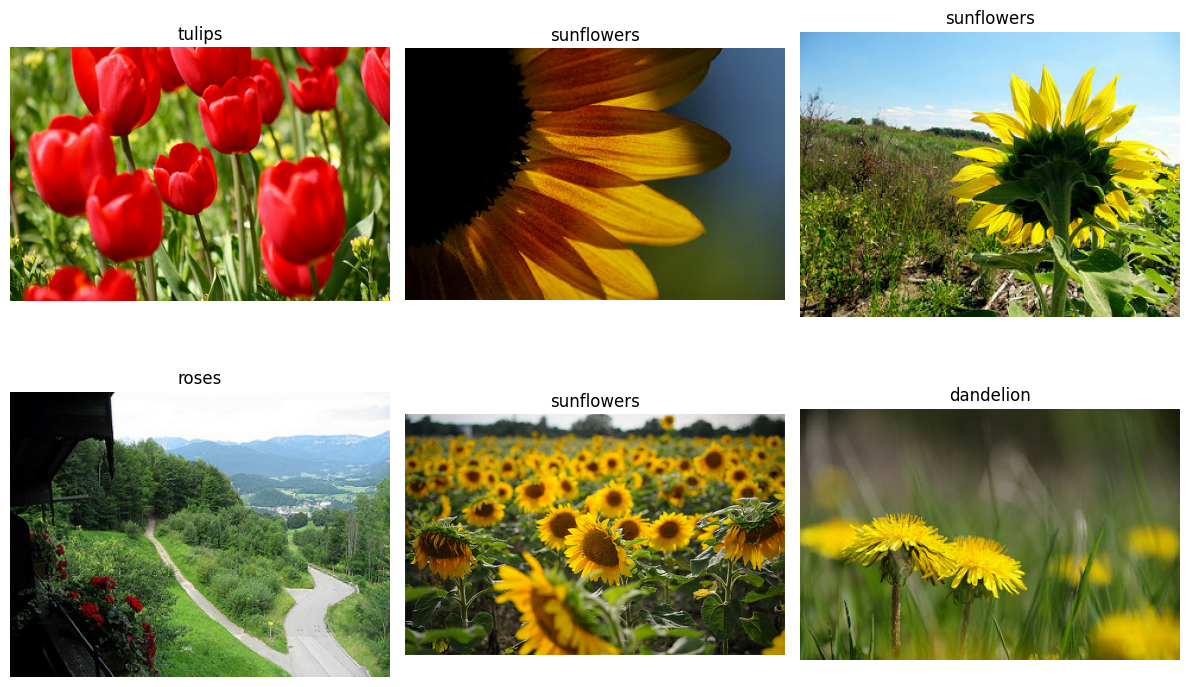

In [ ]:
# VISUALISATION DE QUELQUES IMAGES BRUTES
class_names = info.features["label"].names

plt.figure(figsize=(12, 8))
for i, (image, label) in enumerate(data.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")
plt.tight_layout()

In [ ]:
# Q2) OBSERVER LA SHAPE D'ORIGINE DE QUELQUES IMAGES

for i, (image, label) in enumerate(data.take(3)):
    print(f"Image {i} -> shape : {image.shape}, label : {label.numpy()} ({class_names[label.numpy()]})")

Image 0 -> shape : (333, 500, 3), label : 2 (tulips)
Image 1 -> shape : (212, 320, 3), label : 3 (sunflowers)
Image 2 -> shape : (240, 320, 3), label : 3 (sunflowers)


**Q2)** Les images n’ont pas la même taille.

   Importance de vérification:
→ un CNN exige des dimensions uniformes
→ Nécessité du redimensionnement

In [ ]:
# Q3) CONVERSION DU DATASET EN LISTES / TABLEAUX

images = []
labels = []

for image, label in tfds.as_numpy(data):
    images.append(image)
    labels.append(label)

images = np.array(images, dtype=object)
labels = np.array(labels)

print("Nombre d'images :", len(images))
print("Nombre de labels :", len(labels))

Nombre d'images : 3670
Nombre de labels : 3670


**Q3)** Cette transformation consiste à convertir le tf.data.Dataset en tableaux NumPy afin de disposer de structures manipulables directement en mémoire. Cela facilite les étapes de prétraitement (normalisation, redimensionnement) ainsi que le découpage des données en ensembles d’entraînement et de test (par exemple via train_test_split). Elle permet également d’utiliser directement ces données avec des outils et fonctions qui requièrent des entrées sous forme de tableaux NumPy.




In [ ]:
# 4) REDIMENSIONNEMENT ET NORMALISATION
processed_images = []
for image in images:
    # Redimensionner toutes les images à 128x128
    image_resized = tf.image.resize(image, (128, 128))
    # Convertir en float32 puis normaliser entre 0 et 1
    image_resized = tf.cast(image_resized, tf.float32) / 255.0
    processed_images.append(image_resized.numpy())
processed_images = np.array(processed_images)

print("Shape après prétraitement :", processed_images.shape)
print("Shape d'une image prétraitée :", processed_images[0].shape)
print("Valeur min :", processed_images[0].min())
print("Valeur max :", processed_images[0].max())

Shape après prétraitement : (3670, 128, 128, 3)
Shape d'une image prétraitée : (128, 128, 3)
Valeur min : 0.0
Valeur max : 1.0


**Q4)** La conversion en float32 est indispensable avant la normalisation car les opérations en Deep Learning nécessitent des valeurs continues et une précision décimale. La normalisation consiste à diviser les pixels par 255 afin de les ramener dans l’intervalle [0,1], ce qui n’est correctement représentable qu’en type flottant.

Si les images restent en type entier (uint8 ou int8), la division par 255 entraînera une perte d’information due à la troncature : la majorité des valeurs seront arrondies à 0 (et éventuellement 1 pour 255), ce qui détruit la dynamique des intensités de pixels.

En pratique, travailler en float32 permet :

*   de conserver la précision des valeurs normalisées ;
*   de stabiliser l’apprentissage (meilleure propagation du gradient) ;
*   d’assurer la compatibilité avec les modèles de Deep Learning, qui attendent des entrées flottantes.





In [ ]:
# 5) DÉCOUPAGE TRAIN / VALIDATION / TEST

X_train, X_temp, y_train, y_temp = train_test_split(
    processed_images,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

print("y_train :", y_train.shape)
print("y_val   :", y_val.shape)
print("y_test  :", y_test.shape)

X_train : (2569, 128, 128, 3)
X_val   : (550, 128, 128, 3)
X_test  : (551, 128, 128, 3)
y_train : (2569,)
y_val   : (550,)
y_test  : (551,)


In [ ]:
# 6) DATA AUGMENTATION
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

**Q6)** L’étape de data augmentation est essentielle dans le cas du dataset Flowers, car ce type de données présente une forte variabilité naturelle (orientation, échelle, point de vue, conditions de prise de vue), tandis que la taille du dataset reste limitée pour entraîner efficacement un modèle profond.

Elle permet de générer dynamiquement de nouvelles variations des images à partir des données existantes, ce qui améliore la capacité de généralisation du modèle, le rend plus robuste aux variations et réduit le risque de surapprentissage (overfitting).

Les transformations appliquées jouent chacune un rôle spécifique :


* RandomFlip("horizontal") : applique une symétrie horizontale (effet miroir), rendant le modèle invariant à l’orientation gauche/droite.
* RandomRotation(0.1) : applique une rotation aléatoire pouvant aller jusqu’à environ ±36°, simulant des variations d’angle de prise de vue.
* RandomZoom(0.1) : applique un zoom aléatoire (avant ou arrière), permettant de gérer les variations d’échelle.

Ces transformations sont appliquées de manière aléatoire et successive à chaque passage des données dans le modèle. Ainsi, à chaque epoch (et même à chaque batch), une même image peut apparaître sous différentes formes. Une image peut donc subir plusieurs transformations combinées ou seulement une partie d’entre elles.

In [ ]:
# 7) CONSTRUCTION DU MODÈLE CNN MULTICLASSE SIMPLE
model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(5, activation="softmax")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

**Q7) Quel est l’intérêt d’augmenter progressivement le nombre de filtres (32 → 64 → 128) dans le modèle ?** Dans ce modèle CNN, le nombre de filtres augmente progressivement de 32 à 64 puis 128 afin de permettre au réseau d’apprendre des caractéristiques de plus en plus riches et abstraites. Au début du réseau, les premières couches convolutionnelles détectent surtout des caractéristiques simples : contours, couleurs, textures ou petites formes locales. À mesure que l’on avance dans le réseau, les dimensions spatiales des images diminuent grâce au MaxPooling2D, mais les informations extraites deviennent plus complexes. Il est donc logique d’augmenter le nombre de filtres pour permettre au modèle de représenter davantage de motifs visuels : formes de pétales, structures de fleurs, combinaisons de textures, etc. Autrement dit, plus on avance dans le CNN, plus l’image est résumée spatialement, mais plus le nombre de cartes de caractéristiques augmente. Cela permet au modèle de compenser la réduction de taille par une représentation plus riche en profondeur.

**Quel est le rôle de la couche GlobalAveragePooling2D() ?** La couche GlobalAveragePooling2D intervient après la dernière opérations couche de maxpooling. À ce stade, l’entrée de cette couche est un tenseur de dimension (16,16,128), ce qui signifie que le réseau a extrait 128 cartes de caractéristiques de taille (16,16). La couche GlobalAveragePooling2D calcule alors la moyenne des valeurs de chaque carte de caractéristiques, réduisant ainsi chaque matrice 16×16 à une seule valeur. Le résultat est un vecteur de taille 128, où chaque composante résume la présence globale d’un motif dans l’image, indépendamment de sa position. Contrairement au MaxPooling2D, qui agit localement sur les dimensions spatiales, cette couche effectue une agrégation globale et supprime complètement la dimension spatiale. Elle permet ainsi de réduire le nombre de paramètres, d’éviter l’utilisation d’une couche Flatten coûteuse, et de produire une représentation compacte et adaptée à la classification finale.

**Q8)**
Pour une couche Conv2D, le nombre de paramètres dépend de la taille du filtre, du nombre de canaux d’entrée et du nombre de filtres utilisés.

**_Prenons par exemple la première couche** : Conv2D(32, (3,3)) avec une entrée de dimension (128,128,3). Le calcul du nombre de paramètres est :
                    (3×3×3)×32+32=864+32=896

Pour une couche Dense, le nombre de paramètres dépend du nombre d’entrées et du nombre de neurones.

**_Prenons l'exemple de la couche : Dense(128)** avec une entrée de taille 128. Le calcul est :
                128×128+128=16384+128=16512

**Analyse de l'évolution globale du nombre total de paramètres dans le modèle:**
_Les couches convolutionnelles voient leur nombre de paramètres augmenter (896 → 18 496 → 73 856) car : le nombre de filtres augmente (32 → 64 → 128) et le nombre de canaux d’entrée augmente également.
_Après la couche GlobalAveragePooling2D, le nombre de paramètres chute fortement car la dimension spatiale est supprimée (on passe de (16×16×128) à 128). Les couches Dense contiennent encore un nombre significatif de paramètres, mais bien inférieur à ce qu’aurait produit un Flatten.

In [ ]:
# 9) COMPILATION DU MODÈLE
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# CALLBACKS : EARLY STOPPING + REDUCE LR

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

**Q9)** Le callback ReduceLROnPlateau sert à ajuster automatiquement le taux d’apprentissage pendant l’entraînement. Dans ce code, il surveille la valeur de val_loss. Si cette perte de validation ne s’améliore pas pendant 3 epochs (patience=3), le taux d’apprentissage est réduit de moitié (factor=0.5).

Son rôle est donc de ralentir l’apprentissage lorsque le modèle atteint un plateau. Au début, un learning rate de 0.001 permet d’apprendre rapidement. Mais si la validation stagne, un learning rate plus faible permet au modèle de faire des mises à jour plus fines des poids et de chercher une meilleure solution.

Le paramètre min_lr=1e-6 fixe une limite minimale : le learning rate ne descendra pas en dessous de cette valeur. Ainsi, ReduceLROnPlateau permet d’améliorer la convergence du modèle, de stabiliser l’entraînement et d’éviter que le modèle reste bloqué avec un taux d’apprentissage trop élevé.

In [ ]:
# 10) ENTRAÎNEMENT DU MODÈLE

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.3429 - loss: 1.4398 - val_accuracy: 0.4564 - val_loss: 1.2651 - learning_rate: 0.0010
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.4492 - loss: 1.2595 - val_accuracy: 0.4873 - val_loss: 1.1720 - learning_rate: 0.0010
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.5115 - loss: 1.1864 - val_accuracy: 0.5036 - val_loss: 1.1533 - learning_rate: 0.0010
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.5364 - loss: 1.1236 - val_accuracy: 0.5527 - val_loss: 1.0655 - learning_rate: 0.0010
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - accuracy: 0.5738 - loss: 1.0622 - val_accuracy: 0.5636 - val_loss: 1.0342 - learning_rate: 0.0010
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.5886 - loss: 1.0386 - val_accuracy: 0.5909 - val_loss: 1.0270 - learning_rate: 0.0010
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.5998 - loss: 1.0138 - val_acc

**Q10)** Réponse :
Plusieurs éléments de l’architecture et du pipeline peuvent ralentir l’entraînement du modèle :

* La taille des images (128×128×3) : des images relativement grandes augmentent le coût des opérations de convolution, ce qui ralentit chaque itération.
* Le nombre croissant de filtres (32 → 64 → 128) : plus le nombre de filtres est élevé, plus le nombre de calculs et de paramètres augmente, en particulier dans les dernières couches convolutionnelles.
* La couche de data augmentation : les transformations (flip, rotation, zoom) sont appliquées dynamiquement à chaque batch, ce qui ajoute un coût de calcul supplémentaire avant même le passage dans le réseau.
*  La profondeur du réseau (plusieurs blocs Conv + Pooling) : chaque couche ajoute du temps de calcul, surtout les convolutions qui sont coûteuses.

En revanche, la couche GlobalAveragePooling2D permet de réduire fortement la complexité du modèle. En effet, sans cette couche (en utilisant un Flatten), la sortie serait de taille 16×16×128=32768 features, ce qui entraînerait un très grand nombre de paramètres dans les couches Dense. Avec GlobalAveragePooling2D, cette représentation est réduite à un vecteur de taille 128, ce qui diminue le nombre de calculs dans les couches fully connected, accélère l’entraînement et rend le modèle plus léger.
Cependant, dans certains cas, cette réduction peut être trop importante et entraîner une perte d’information spatiale, ce qui peut limiter la capacité du modèle à capturer des détails fins et impacter légèrement les performances.


In [ ]:
# 11) ÉVALUATION GLOBALE SUR LE JEU DE TEST

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Loss sur test :", test_loss)
print("Accuracy sur test :", test_accuracy)

18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 490ms/step - accuracy: 0.6334 - loss: 0.9275
Loss sur test : 0.9275190234184265
Accuracy sur test : 0.6333938241004944


In [ ]:
# 12) PRÉDICTION SUR TOUT LE JEU DE TEST
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
print("5 premières classes prédites :", y_pred[:5])
print("5 premières classes réelles  :", y_test[:5])

18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 293ms/step
5 premières classes prédites : [2 3 2 4 3]
5 premières classes réelles  : [2 0 2 4 2]


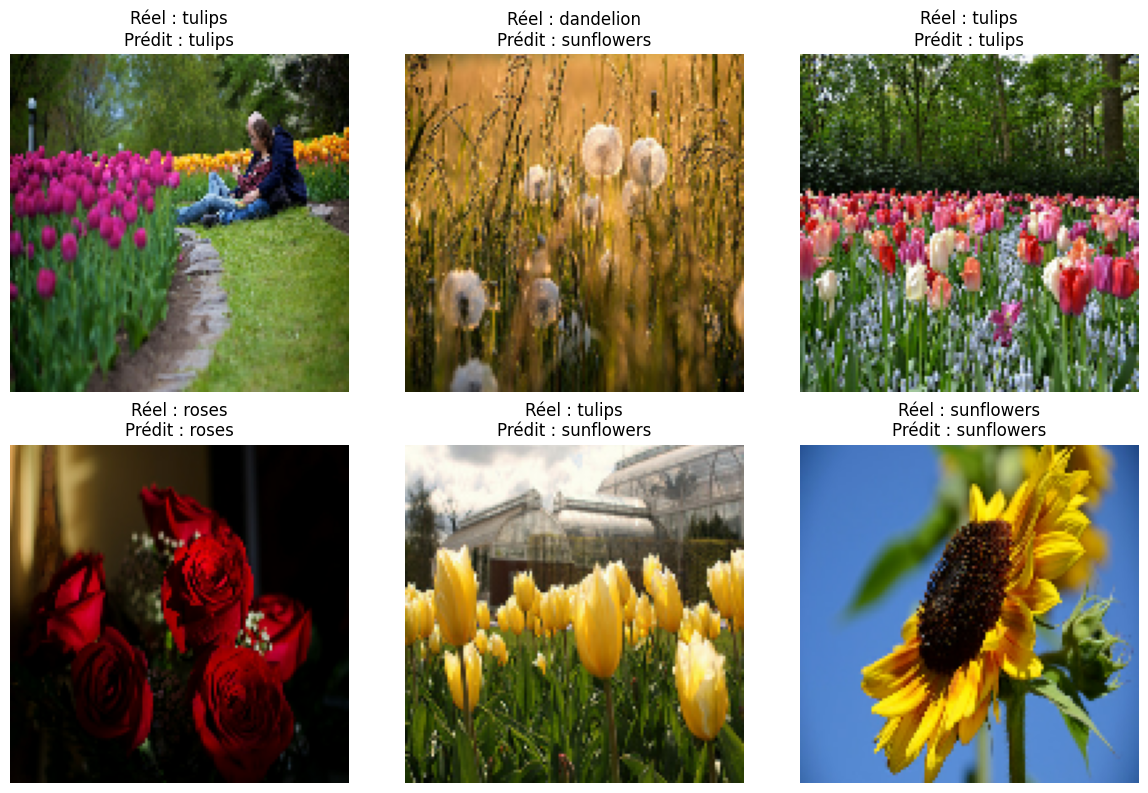

In [ ]:
# AFFICHAGE DE QUELQUES EXEMPLES RÉEL / PRÉDIT
plt.figure(figsize=(12, 8))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"Réel : {class_names[y_test[i]]}\nPrédit : {class_names[y_pred[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

**Q12)**
**1)** La méthode evaluate permet de mesurer les performances globales du modèle sur un dataset (généralement de test). Elle calcule des métriques comme la perte (loss) et l’accuracy en comparant automatiquement les prédictions du modèle avec les vraies étiquettes. Elle retourne uniquement des valeurs numériques globales et ne permet pas d’accéder aux prédictions individuelles.
En revanche, la méthode predict sert à générer explicitement les sorties du modèle (probabilités ou classes prédites) pour des données données, sans calculer de métriques. Elle est utilisée pour analyser les résultats et visualiser les prédictions.

**2)** Comparaison entre classes réelles et prédites:
En observant les images affichées, on remarque que le modèle est capable de faire quelques prédictions correctes. Cependant, certaines erreurs apparaissent. Cela montre que le modèle confond parfois certaines classes, notamment lorsque les caractéristiques visuelles sont proches (forme, couleur, texture).

**3)** Conclusion: le modèle n’est pas toujours correct.Ces erreurs peuvent s’expliquer par :
* des similarités visuelles entre certaines classes
*  une variabilité des images (angle, éclairage, arrière-plan)
*  et des limites du modèle (entraînement insuffisant)

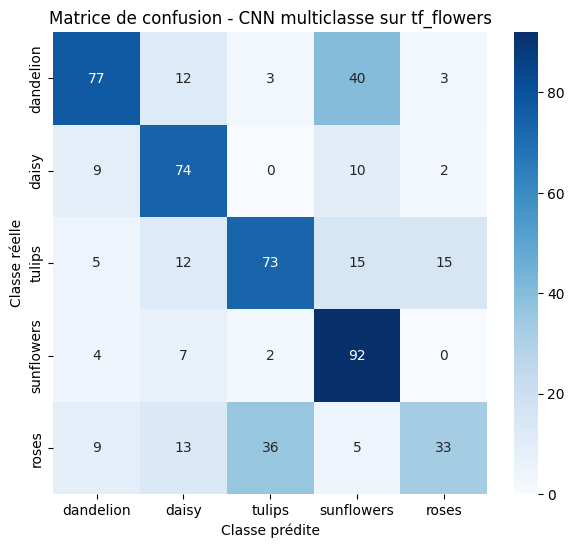

Matrice de confusion :
[[77 12  3 40  3]
 [ 9 74  0 10  2]
 [ 5 12 73 15 15]
 [ 4  7  2 92  0]
 [ 9 13 36  5 33]]


In [ ]:
# 13) MATRICE DE CONFUSION
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names )
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.title("Matrice de confusion - CNN multiclasse sur tf_flowers")
plt.show()
print("Matrice de confusion :")
print(cm)

**Q13)**
**1)** Les valeurs situées sur la diagonale de la matrice de confusion correspondent aux prédictions correctes du modèle. Chaque valeur indique le nombre d’images d’une classe donnée qui ont été correctement classifiées dans cette même classe.

**2) Faux positifs et faux négatifs (exemple : classe “tulips”)**
On regarde la ligne “tulips” (sans la diagonale) :
5 → prédit dandelion
12 → prédit daisy
15 → prédit sunflowers
15 → prédit roses
**Donc: FN=5+12+15+15=47**.
Si on regarde la colonne “tulips” (sans la diagonale) :
3 → réel dandelion
0 → réel daisy
2 → réel sunflowers
36 → réel roses
**Donc: FP=3+0+2+36=41**

**3) Classe la mieux prédite et la plus difficile:**
* La classe la mieux prédite est sunflowers, car elle présente le taux de bonnes prédictions le plus élevé par rapport au nombre total d’exemples de la classe (recall élevé, environ 88%).

* Les classes les plus difficiles à classifier sont roses et dandelion :
    _roses : seulement 33 bonnes prédictions sur 96 → recall ≈ 34%
    _dandelion : 77 bonnes prédictions sur 135 → recall ≈ 57%. Ces classes présentent un nombre important de confusions avec d’autres classes (notamment tulips et sunflowers), ce qui montre que leurs caractéristiques visuelles sont moins discriminantes pour le modèle.

In [ ]:
# RAPPORT DE CLASSIFICATION
print("Rapport de classification :\n")
print(classification_report(y_test, y_pred, target_names=class_names))
report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        output_dict=True
    )
).transpose()
print(report_df.round(3))

Rapport de classification :

              precision    recall  f1-score   support

   dandelion       0.74      0.57      0.64       135
       daisy       0.63      0.78      0.69        95
      tulips       0.64      0.61      0.62       120
  sunflowers       0.57      0.88      0.69       105
       roses       0.62      0.34      0.44        96

    accuracy                           0.63       551
   macro avg       0.64      0.64      0.62       551
weighted avg       0.65      0.63      0.62       551

              precision  recall  f1-score  support
dandelion         0.740   0.570     0.644  135.000
daisy             0.627   0.779     0.695   95.000
tulips            0.640   0.608     0.624  120.000
sunflowers        0.568   0.876     0.689  105.000
roses             0.623   0.344     0.443   96.000
accuracy          0.633   0.633     0.633    0.633
macro avg         0.640   0.636     0.619  551.000
weighted avg      0.646   0.633     0.622  551.000


# **PARTIE II: Transfer Learning**

**Q1)** Le Transfer Learning consiste à exploiter un modèle pré-entraîné sur un large jeu de données générique (tel que ImageNet) afin de l’adapter à une nouvelle tâche spécifique. Dans le contexte de la classification d’images, les premières couches convolutionnelles de ces modèles apprennent des caractéristiques générales et réutilisables, comme la détection de contours, de textures ou de formes simples, tandis que les couches plus profondes capturent des représentations plus complexes. En réutilisant ces connaissances, on évite de réentraîner un modèle depuis zéro, ce qui permet de réduire significativement le temps d’entraînement, les besoins en données et les ressources de calcul. Cette approche améliore également les performances, en particulier lorsque le nouveau jeu de données est de taille limitée, tout en favorisant une meilleure capacité de généralisation du modèle.

In [ ]:
# Charger MobileNetV2 sans la partie classification
base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Gener les couches: on garde les features déjà apprises
for layer in base_model.layers:
    layer.trainable = False

In [ ]:
# On ajoute une tête de classification
model_tl = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(5, activation="softmax")
])

In [ ]:
model_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_tl = model_tl.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 48s 520ms/step - accuracy: 0.6979 - loss: 0.8415 - val_accuracy: 0.8673 - val_loss: 0.4030
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 79s 490ms/step - accuracy: 0.8447 - loss: 0.4261 - val_accuracy: 0.8800 - val_loss: 0.3736
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 546ms/step - accuracy: 0.8867 - loss: 0.3220 - val_accuracy: 0.8891 - val_loss: 0.3162
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 40s 495ms/step - accuracy: 0.9070 - loss: 0.2663 - val_accuracy: 0.8836 - val_loss: 0.3218
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 545ms/step - accuracy: 0.9194 - loss: 0.2175 - val_accuracy: 0.8945 - val_loss: 0.2929
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 39s 488ms/step - accuracy: 0.9420 - loss: 0.1713 - val_accuracy: 0.8927 - val_loss: 0.2804
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 43s 525ms/step - accuracy: 0.9451 - loss: 0.1554 - val_accuracy: 0.9073 - val_loss: 0.2859
Epoch 8/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 40s 493ms/step - accuracy: 0.9568 - loss: 0.1283 - val_accu

In [ ]:
test_loss_tl, test_acc_tl = model_tl.evaluate(X_test, y_test)

print("Accuracy Transfer Learning :", test_acc_tl)

18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 487ms/step - accuracy: 0.8820 - loss: 0.3465
Accuracy Transfer Learning : 0.8820326924324036


In [ ]:
print("CNN from scratch :", test_accuracy)
print("Transfer Learning :", test_acc_tl)

CNN from scratch : 0.6333938241004944
Transfer Learning : 0.8820326924324036


In [ ]:
y_pred_prob_tl = model_tl.predict(X_test)
y_pred_tl = np.argmax(y_pred_prob_tl, axis=1)

print("5 premières classes prédites :", y_pred_tl[:5])
print("5 premières classes réelles  :", y_test[:5])

18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step
5 premières classes prédites : [2 0 2 4 2]
5 premières classes réelles  : [2 0 2 4 2]


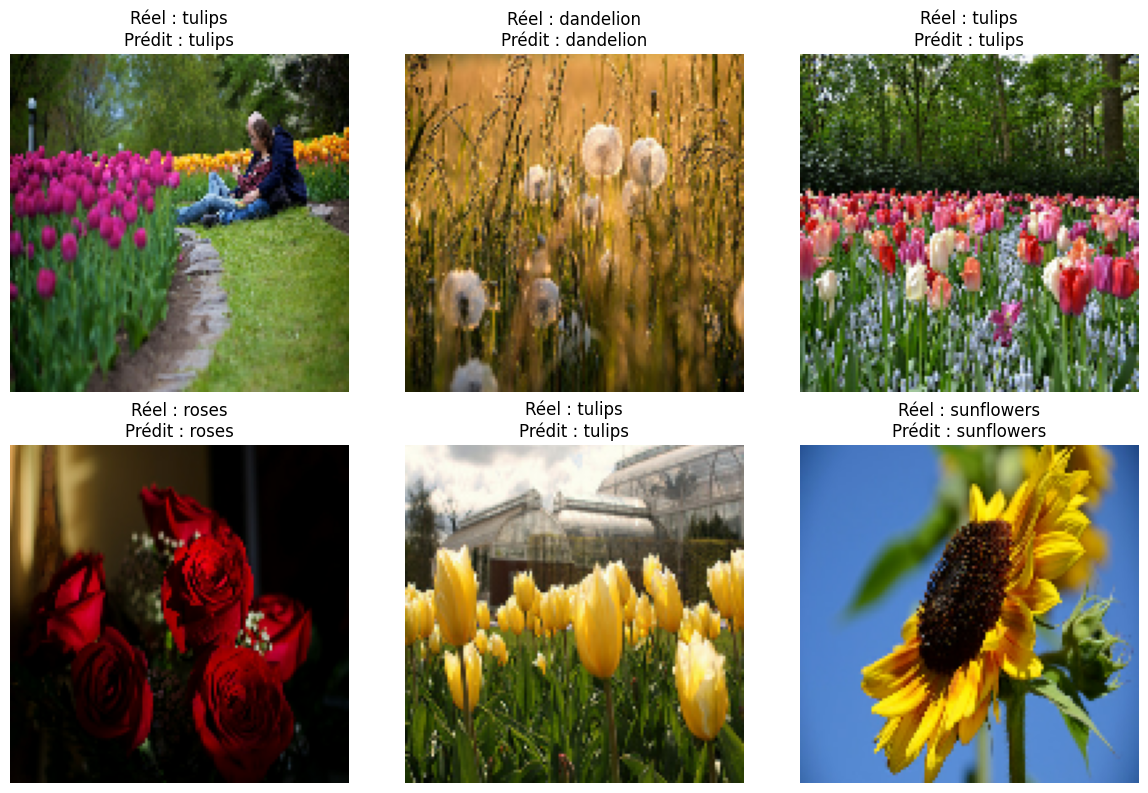

In [ ]:
# AFFICHAGE DE QUELQUES EXEMPLES RÉEL / PRÉDIT
plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"Réel : {class_names[y_test[i]]}\nPrédit : {class_names[y_pred_tl[i]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

**Q3-1) Architecture MobileNetV2 et dataset d’entraînement**
**MobileNetV2** est un réseau de neurones convolutionnel (CNN) conçu pour être léger et efficace en calcul. Contrairement aux CNN classiques, qui appliquent directement des couches de convolution suivies de pooling avec une augmentation progressive du nombre de canaux, MobileNetV2 introduit une architecture plus optimisée basée sur des blocs spécifiques.

Chaque bloc de MobileNetV2 suit une logique en trois étapes :

* une expansion (convolution 1×1) qui augmente le nombre de canaux pour enrichir la représentation,
* une convolution depthwise qui traite les caractéristiques de manière efficace,
* une compression (convolution 1×1, appelée bottleneck) qui réduit le nombre de canaux afin de limiter le coût de calcul.

Cette stratégie, appelée inverted residual, consiste donc à élargir temporairement la représentation avant de la compresser, ce qui permet de capturer plus d’informations tout en gardant un modèle léger.

**Le modèle est généralement pré-entraîné sur le dataset ImageNet**, qui contient plus d’un million d’images réparties en environ 1000 classes. Cela lui permet d’apprendre des caractéristiques visuelles générales réutilisables pour d’autres tâches, comme la classification de fleurs.

**Q3_2) Pourquoi gèle-t-on les couches (trainable=False) ?**
On gèle les couches du modèle pré-entraîné afin de conserver les connaissances déjà apprises (features générales comme contours, textures, formes). Ainsi, seules les couches ajoutées (classification finale) sont entraînées, ce qui rend le processus plus stable et efficace.

**Q3_3) Pourquoi réutiliser des caractéristiques ImageNet ?**

Les modèles entraînés sur ImageNet apprennent des caractéristiques visuelles génériques et transférables (bords, textures, motifs simples) qui sont communes à de nombreuses tâches de vision par ordinateur. Ainsi, même si le problème change (ex : fleurs au lieu d’objets généraux), ces représentations restent pertinentes, car :
* les premières couches capturent des motifs universels;
* seules les couches finales doivent être adaptées à la nouvelle tâche.

**Q3_4) Pourquoi le modèle basé sur le Transfer Learning donne-t-il de meilleurs résultats que le CNN entraîné from scratch ?**

Le modèle basé sur le Transfer Learning donne de meilleurs résultats car :
* il démarre avec des poids déjà optimisés
* il nécessite moins de données pour apprendre
* il converge plus rapidement et évite le surapprentissage

À l’inverse, un modèle entraîné from scratch doit apprendre toutes les caractéristiques depuis zéro, ce qui est difficile avec un dataset limité comme Flowers.

**Q3_5) Observation des prédictions:**

En observant les images réelles et prédites, on constate que le modèle basé sur le Transfer Learning a correctement classifié les images affichées. Cela montre une amélioration notable par rapport au modèle précédent, avec moins d’erreurs et une meilleure capacité de reconnaissance.